# Neural Networks for Computer Vision 

## Project - Tree Species Classification

## Individual Project Work

## Day 01 - Project Setup and Dataset Exploration (17.09.2026)

### Step 1. Dataset Exploration

The aim of this project is to develop an image classification model for tree species recognition.

On the first day, I set up the project environment and explored the provided dataset before starting model development. The dataset is already divided into training, validation, and test sets.

The purpose of this initial exploration is to understand the dataset structure, classes, number of images, class distribution, image characteristics, and data quality.

In [4]:
import os

print(os.getcwd())

d:\HAMK\Year 3\Module 1\Neural Networks for Computer Vision\Project\Notebooks


### Step 2 - Check that Python can find the dataset

In [6]:
from pathlib import Path

data_path = Path("../Data/archive/tree")

print("Dataset exists:", data_path.exists())
print("Folders:", [folder.name for folder in data_path.iterdir()])

Dataset exists: True
Folders: ['test', 'train', 'val']


#### Count the tree species

In [7]:
train_path = data_path / "train"

classes = sorted([folder.name for folder in train_path.iterdir() if folder.is_dir()])

print("Number of tree species:", len(classes))
print("\nTree species:")
for species in classes:
    print(species)

Number of tree species: 23

Tree species:
Acer palmatum
Cedrus deodara
Celtis sinensis
Cinnamomum camphora (Linn) Presl
Elaeocarpus decipiens
Flowering cherry
Ginkgo biloba
Koelreuteria paniculata
Lagerstroemia indica
Liquidambar formosana
Liriodendron chinense
Magnolia grandiflora L
Magnolia liliflora Desr
Michelia chapensis
Osmanthus fragrans
Photinia serratifolia
Platanus
Prunus cerasifera f. atropurpurea
Salix babylonica
Sapindus saponaria
Styphnolobium japonicum
Triadica sebifera
Zelkova serrata


**Dataset observation:**

- The training dataset contains 23 tree-species classes. 

- Each species is stored in its own folder, which can later be used as the class label for image classification.

In [8]:
for split in ["train", "val", "test"]:
    split_path = data_path / split

    split_classes = sorted([
        folder.name for folder in split_path.iterdir()
        if folder.is_dir()
    ])

    print(f"{split}: {len(split_classes)} species")

train: 23 species
val: 23 species
test: 23 species


In [9]:
train_classes = sorted([
    folder.name for folder in (data_path / "train").iterdir()
    if folder.is_dir()
])

val_classes = sorted([
    folder.name for folder in (data_path / "val").iterdir()
    if folder.is_dir()
])

test_classes = sorted([
    folder.name for folder in (data_path / "test").iterdir()
    if folder.is_dir()
])

print("Train and validation classes match:", train_classes == val_classes)
print("Train and test classes match:", train_classes == test_classes)

Train and validation classes match: True
Train and test classes match: True


#### Class Consistency Check

The `training`, `validation`, and `test` sets each contain `23 tree species`. The class names are consistent across all three datasets, which confirms that the same classification categories are available for training, validation, and final testing.

#### Count the images

In [10]:
for split in ["train", "val", "test"]:
    split_path = data_path / split

    image_count = sum(
        1 for file in split_path.rglob("*")
        if file.is_file()
    )

    print(f"{split}: {image_count} images")

train: 3850 images
val: 482 images
test: 472 images


### Dataset Split Observation

The dataset contains 23 tree species with a total of 4,804 images:

- Training set: 3,850 images
- Validation set: 482 images
- Test set: 472 images

The training set will be used to train the model, the validation set will be used to evaluate the model during development, and the test set will be reserved for final model evaluation.

### Step 3 - Check class balance

In [11]:
class_counts = {}

for species in classes:
    species_path = train_path / species
    
    count = sum(
        1 for file in species_path.iterdir()
        if file.is_file()
    )
    
    class_counts[species] = count

for species, count in class_counts.items():
    print(f"{species}: {count}")

Acer palmatum: 162
Cedrus deodara: 125
Celtis sinensis: 188
Cinnamomum camphora (Linn) Presl: 234
Elaeocarpus decipiens: 172
Flowering cherry: 106
Ginkgo biloba: 228
Koelreuteria paniculata: 223
Lagerstroemia indica: 65
Liquidambar formosana: 168
Liriodendron chinense: 182
Magnolia grandiflora L: 212
Magnolia liliflora Desr: 190
Michelia chapensis: 154
Osmanthus fragrans: 173
Photinia serratifolia: 120
Platanus: 193
Prunus cerasifera f. atropurpurea: 99
Salix babylonica: 136
Sapindus saponaria: 224
Styphnolobium japonicum: 157
Triadica sebifera: 154
Zelkova serrata: 185


### Class Distribution Observation

The number of training images is not equal across all 23 tree species.

For example, `Cinnamomum camphora (Linn) Presl` has 234 training images, while `Lagerstroemia indica` has only 65. Therefore, the training dataset has some `class imbalance`.

At this stage, I will keep the original dataset unchanged. After training the model, I can investigate whether classes with fewer training images are associated with more classification errors.

### Step 4 - Display sample tree images

**I want to find out:**

What do the images actually look like, and how different are the tree species visually?

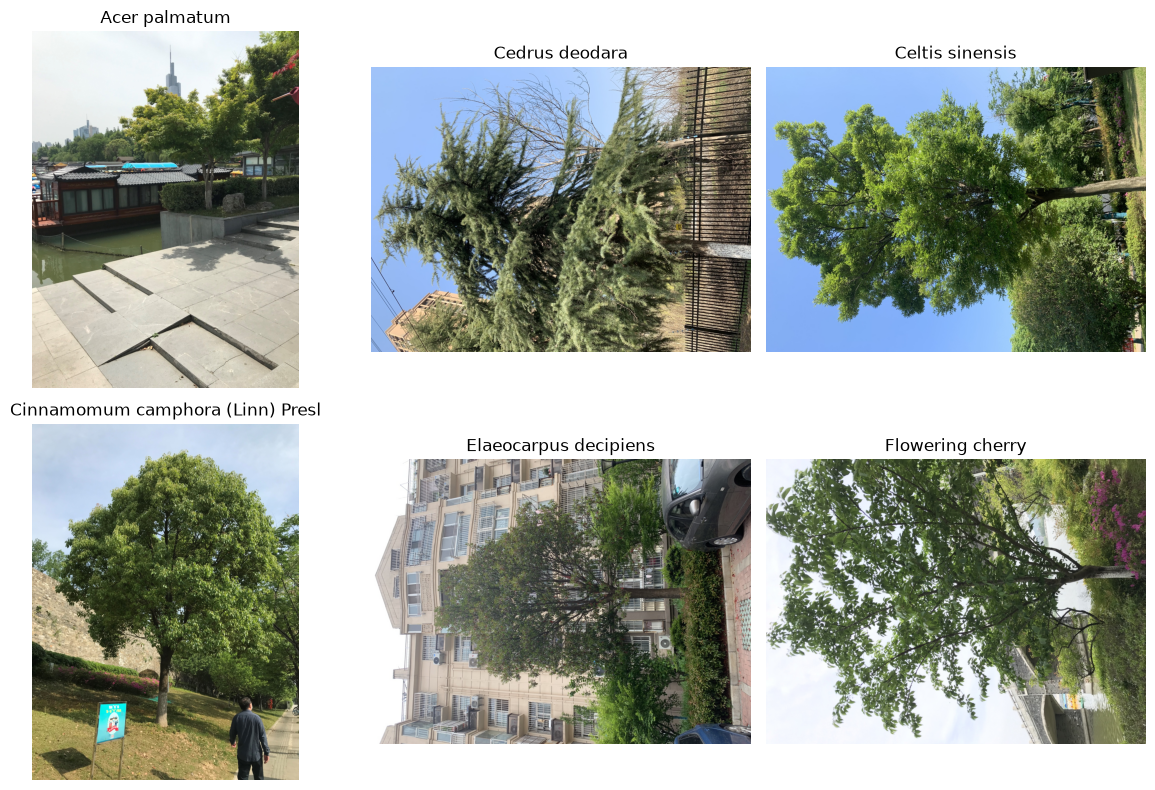

In [12]:
import matplotlib.pyplot as plt
from PIL import Image

# Show one training image from the first 6 tree species
sample_classes = classes[:6]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, species in zip(axes.flatten(), sample_classes):
    species_path = train_path / species
    
    image_files = [
        file for file in species_path.iterdir()
        if file.is_file()
    ]
    
    img = Image.open(image_files[0])
    
    ax.imshow(img)
    ax.set_title(species)
    ax.axis("off")

plt.tight_layout()
plt.show()

**Note:**

It is important to study the images before deciding on preprocessing.

- The images are `not all the same orientation` and several images appear rotated sideways.
- Trees appear at `different sizes and positions`.
- Some images show the `whole tree`, while  others show mainly branches or foliage.
- `Background objects` such as buildings, roads, sky, and other vegetation are present.
- Lighting and viewing angles vary.
- Some tree species may be visually similar.

These variations may make classification more challenging. Later, after learning CNNs and transfer learning, I will investigate suitable preprocessing and augmentation techniques and study the model's classification errors.

### Step 5 - Check image dimensions

In [13]:
from collections import Counter

image_sizes = []

for species in classes:
    species_path = train_path / species

    for image_file in species_path.iterdir():
        if image_file.is_file():
            with Image.open(image_file) as img:
                image_sizes.append(img.size)

size_counts = Counter(image_sizes)

print("Number of different image sizes:", len(size_counts))
print("Most common image sizes:")

for size, count in size_counts.most_common(10):
    print(f"{size}: {count} images")

Number of different image sizes: 63
Most common image sizes:
(1600, 1200): 3602 images
(1200, 1600): 163 images
(1199, 1600): 20 images
(1283, 1600): 2 images
(973, 1600): 2 images
(1350, 1600): 2 images
(1275, 1600): 2 images
(1133, 1600): 2 images
(1250, 1600): 1 images
(1404, 1600): 1 images


### Image Size Observation

The training dataset contains 63 different image dimensions.

`Most training images (3,602 images)` have a size of `1600 × 1200` pixels. Some images have different dimensions, including `1200 × 1600`.

Therefore, the images are not completely uniform in size or orientation. Before training a neural network, suitable resizing and/or cropping will be needed so that the model receives images with a consistent input size.

### Step 6 - Check for corrupted/unreadable images

In [14]:
from PIL import Image

bad_images = []

for split in ["train", "val", "test"]:
    split_path = data_path / split

    for image_file in split_path.rglob("*"):
        if image_file.is_file():
            try:
                with Image.open(image_file) as img:
                    img.verify()
            except Exception as e:
                bad_images.append((image_file, str(e)))

print("Number of unreadable/corrupted images:", len(bad_images))

if bad_images:
    for file, error in bad_images:
        print(file, error)

Number of unreadable/corrupted images: 0


### Image Integrity Check

All training, validation, and test images were checked for unreadable or corrupted files.

No corrupted or unreadable images were found. Therefore, no images need to be removed from the dataset at this stage.

# Day 02 - CNN Experiment (21.09.2026)

## Step 1. Preparing the Dataset for CNN

After learning the basic concepts of Convolutional Neural Networks (CNNs), I will apply them to the tree species dataset.

The dataset will first be prepared using image transformations and PyTorch DataLoaders so that it can be used for CNN training.

### Step 1 - Import what we need for image preparation

In [15]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

### Step 2 - Define image transformations

In [16]:
IMG_SIZE = 128

train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])

val_test_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])

### Step 3 - Load the tree datasets with `ImageFolder`

In [17]:
train_ds = datasets.ImageFolder(
    data_path / "train",
    transform=train_tfms
)

val_ds = datasets.ImageFolder(
    data_path / "val",
    transform=val_test_tfms
)

test_ds = datasets.ImageFolder(
    data_path / "test",
    transform=val_test_tfms
)

print("Training images:", len(train_ds))
print("Validation images:", len(val_ds))
print("Test images:", len(test_ds))
print("Number of classes:", len(train_ds.classes))

Training images: 3850
Validation images: 482
Test images: 472
Number of classes: 23


### Step 4 - Create the DataLoaders

In [18]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("DataLoaders created successfully.")

DataLoaders created successfully.


### Step 5 - Inspect one batch

In [19]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("First 10 labels:", labels[:10])

Images shape: torch.Size([32, 3, 128, 128])
Labels shape: torch.Size([32])
First 10 labels: tensor([16,  0,  7, 12, 11, 20, 11, 16,  1, 21])


### Step 6 - See which number belongs to which species

In [20]:
print(train_ds.class_to_idx)

{'Acer palmatum': 0, 'Cedrus deodara': 1, 'Celtis sinensis': 2, 'Cinnamomum camphora (Linn) Presl': 3, 'Elaeocarpus decipiens': 4, 'Flowering cherry': 5, 'Ginkgo biloba': 6, 'Koelreuteria paniculata': 7, 'Lagerstroemia indica': 8, 'Liquidambar formosana': 9, 'Liriodendron chinense': 10, 'Magnolia grandiflora L': 11, 'Magnolia liliflora Desr': 12, 'Michelia chapensis': 13, 'Osmanthus fragrans': 14, 'Photinia serratifolia': 15, 'Platanus': 16, 'Prunus cerasifera f. atropurpurea': 17, 'Salix babylonica': 18, 'Sapindus saponaria': 19, 'Styphnolobium japonicum': 20, 'Triadica sebifera': 21, 'Zelkova serrata': 22}


### Step 7 - Visualize one prepared training image

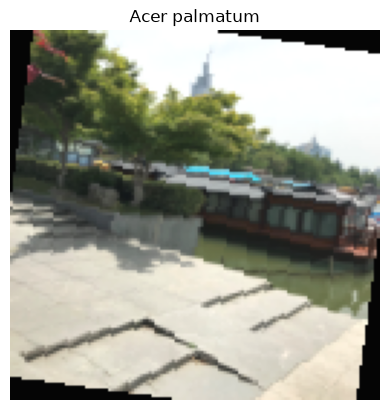

In [21]:
import matplotlib.pyplot as plt

img, label = train_ds[0]

# Reverse the normalization for displaying the image
img_display = img * 0.5 + 0.5

plt.imshow(img_display.permute(1, 2, 0))
plt.title(train_ds.classes[label])
plt.axis("off")
plt.show()

### Step 8 - Build our first Tree CNN 😄😄😄

In [17]:
import torch
import torch.nn as nn

class TreeCNN(nn.Module):
    def __init__(self, num_classes=23):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

### Step 9 - Create the model and test one forward pass

In [18]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = TreeCNN(num_classes=23).to(device)

images = images.to(device)

with torch.no_grad():
    outputs = model(images)

print("Device:", device)
print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Device: cpu
Input shape: torch.Size([32, 3, 128, 128])
Output shape: torch.Size([32, 23])


### Step 10 - Set up loss and optimizer

In [19]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=3e-4,
    weight_decay=1e-4
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)

Loss function: CrossEntropyLoss()
Optimizer: Adam


### Step 11 - Tiny training test

In [20]:
model.train()

x, y = next(iter(train_loader))
x, y = x.to(device), y.to(device)

optimizer.zero_grad()

logits = model(x)
loss = criterion(logits, y)

loss.backward()
optimizer.step()

print("One training batch completed.")
print("Loss:", loss.item())

One training batch completed.
Loss: 3.142130136489868


### Step 12 - Create the training + validation function

In [21]:
def run_epoch(model, loader, training=True):
    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits = model(x)
            loss = criterion(logits, y)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * x.size(0)

        preds = logits.argmax(dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)

    avg_loss = total_loss / total
    accuracy = correct / total

    return avg_loss, accuracy

### Step 13 - Train for ONE full epoch

In [22]:
import time

start_time = time.time()

train_loss, train_acc = run_epoch(
    model, train_loader, training=True
)

val_loss, val_acc = run_epoch(
    model, val_loader, training=False
)

elapsed = time.time() - start_time

print(f"Train loss: {train_loss:.4f}")
print(f"Train accuracy: {train_acc:.3f}")
print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: {val_acc:.3f}")
print(f"Time: {elapsed:.1f} seconds")

Train loss: 3.0970
Train accuracy: 0.059
Validation loss: 3.0368
Validation accuracy: 0.077
Time: 175.2 seconds


### Step 14 - Continue training for 4 more epochs

In [23]:
for epoch in range(2, 6):

    train_loss, train_acc = run_epoch(
        model, train_loader, training=True
    )

    val_loss, val_acc = run_epoch(
        model, val_loader, training=False
    )

    print(
        f"Epoch {epoch}/5 | "
        f"train_loss={train_loss:.4f} "
        f"train_acc={train_acc:.3f} | "
        f"val_loss={val_loss:.4f} "
        f"val_acc={val_acc:.3f}"
    )

Epoch 2/5 | train_loss=2.9509 train_acc=0.109 | val_loss=2.7937 val_acc=0.139
Epoch 3/5 | train_loss=2.8303 train_acc=0.130 | val_loss=2.7138 val_acc=0.172
Epoch 4/5 | train_loss=2.7789 train_acc=0.152 | val_loss=2.6677 val_acc=0.220
Epoch 5/5 | train_loss=2.7336 train_acc=0.165 | val_loss=2.6176 val_acc=0.195


# Day 03 - Transfer Learning with ResNet (23.09.2026)

## Prepare the Data for Pretrained ResNet

### Step 15 - Import ResNet tools

In [22]:
from torchvision import models

weights = models.ResNet18_Weights.DEFAULT

print("Pretrained weights:", weights)

Pretrained weights: ResNet18_Weights.IMAGENET1K_V1


### Step 16 - Prepare Image Transformations for ResNet

In [24]:
from torchvision import transforms

# ImageNet normalization values used by pretrained ResNet
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

# Training transformations
resnet_train_tfms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

# Validation/test transformations
resnet_eval_tfms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

print("ResNet transformations created.")

ResNet transformations created.


### Step 17 - Create ResNet datasets and DataLoaders

Since I don't want to overwrite the TreeCNN datasets, so I'll give these new ones clear `resnet_` names.

#### Step 17.1 - define the three paths

In [27]:
train_dir = data_path / "train"
val_dir   = data_path / "val"
test_dir  = data_path / "test"

print("Train:", train_dir)
print("Validation:", val_dir)
print("Test:", test_dir)

print("Paths exist:",
      train_dir.exists(),
      val_dir.exists(),
      test_dir.exists())

Train: ..\Data\archive\tree\train
Validation: ..\Data\archive\tree\val
Test: ..\Data\archive\tree\test
Paths exist: True True True


#### Step 17.2 - Create ResNet datasets and DataLoaders

In [26]:
from torchvision import datasets
from torch.utils.data import DataLoader

# Create datasets using ResNet transformations
resnet_train_ds = datasets.ImageFolder(
    train_dir,
    transform=resnet_train_tfms
)

resnet_val_ds = datasets.ImageFolder(
    val_dir,
    transform=resnet_eval_tfms
)

resnet_test_ds = datasets.ImageFolder(
    test_dir,
    transform=resnet_eval_tfms
)

# Create DataLoaders
BATCH_SIZE = 32

resnet_train_loader = DataLoader(
    resnet_train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True
)

resnet_val_loader = DataLoader(
    resnet_val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)

resnet_test_loader = DataLoader(
    resnet_test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training images:", len(resnet_train_ds))
print("Validation images:", len(resnet_val_ds))
print("Test images:", len(resnet_test_ds))
print("Number of classes:", len(resnet_train_ds.classes))

Training images: 3850
Validation images: 482
Test images: 472
Number of classes: 23


### Step 18 - Load pretrained ResNet18

In [27]:
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load pretrained ResNet18
resnet18 = models.resnet18(weights=weights)

# Freeze all pretrained layers
for param in resnet18.parameters():
    param.requires_grad = False

# Replace the original final classification layer
num_features = resnet18.fc.in_features
resnet18.fc = nn.Linear(num_features, 23)

# Move model to device
resnet18 = resnet18.to(device)

print("Device:", device)
print("Original features into final layer:", num_features)
print("New final layer:", resnet18.fc)

3.4%

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\Vindy Suba/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


Device: cpu
Original features into final layer: 512
New final layer: Linear(in_features=512, out_features=23, bias=True)


### Step 19 - Check what we're actually training

In [28]:
trainable = []

for name, param in resnet18.named_parameters():
    if param.requires_grad:
        trainable.append(name)

print("Trainable parameters:")
for name in trainable:
    print(name)

Trainable parameters:
fc.weight
fc.bias


### Step 20 - Loss function and optimizer

In [29]:
criterion_resnet = nn.CrossEntropyLoss()

optimizer_resnet = torch.optim.Adam(
    resnet18.fc.parameters(),
    lr=0.001
)

print("Loss function:", criterion_resnet)
print("Optimizer:", optimizer_resnet.__class__.__name__)

Loss function: CrossEntropyLoss()
Optimizer: Adam


### Step 21 - Tiny training test

In [30]:
resnet18.train()

x, y = next(iter(resnet_train_loader))
x, y = x.to(device), y.to(device)

optimizer_resnet.zero_grad()

outputs = resnet18(x)
loss = criterion_resnet(outputs, y)

loss.backward()
optimizer_resnet.step()

print("One ResNet training batch completed.")
print("Input shape:", x.shape)
print("Output shape:", outputs.shape)
print("Loss:", loss.item())

One ResNet training batch completed.
Input shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 23])
Loss: 3.4434189796447754


### Step 22 - Train ResNet18 for 5 epochs

In [31]:
# Reset the final classifier
resnet18.fc = nn.Linear(512, 23).to(device)

# Fresh optimizer
optimizer_resnet = torch.optim.Adam(
    resnet18.fc.parameters(),
    lr=0.001
)

In [32]:
def run_resnet_epoch(model, loader, training=True):
    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        if training:
            optimizer_resnet.zero_grad()

        with torch.set_grad_enabled(training):
            outputs = model(x)
            loss = criterion_resnet(outputs, y)

            if training:
                loss.backward()
                optimizer_resnet.step()

        total_loss += loss.item() * x.size(0)

        preds = outputs.argmax(dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)

    return total_loss / total, correct / total

In [33]:
import time

EPOCHS_RESNET = 5

for epoch in range(1, EPOCHS_RESNET + 1):

    start = time.time()

    train_loss, train_acc = run_resnet_epoch(
        resnet18, resnet_train_loader, training=True
    )

    val_loss, val_acc = run_resnet_epoch(
        resnet18, resnet_val_loader, training=False
    )

    elapsed = time.time() - start

    print(
        f"Epoch {epoch}/{EPOCHS_RESNET} | "
        f"train_loss={train_loss:.4f} "
        f"train_acc={train_acc:.3f} | "
        f"val_loss={val_loss:.4f} "
        f"val_acc={val_acc:.3f} | "
        f"time={elapsed:.1f}s"
    )

Epoch 1/5 | train_loss=2.7780 train_acc=0.209 | val_loss=2.2703 val_acc=0.407 | time=239.2s
Epoch 2/5 | train_loss=2.1352 train_acc=0.423 | val_loss=1.8418 val_acc=0.523 | time=231.6s
Epoch 3/5 | train_loss=1.8208 train_acc=0.518 | val_loss=1.6454 val_acc=0.527 | time=242.1s
Epoch 4/5 | train_loss=1.6321 train_acc=0.558 | val_loss=1.5679 val_acc=0.577 | time=235.6s
Epoch 5/5 | train_loss=1.5164 train_acc=0.586 | val_loss=1.4221 val_acc=0.600 | time=242.9s


**Note:**

ResNet18 transfer learning: 

- After 5 epochs, `validation accuracy` increased from `40.7% to 60.0%`, while `validation loss` decreased from `2.27 to 1.42`. 

- The pretrained model is learning the tree classes successfully.

### Step 23 - Evaluate ResNet18 on the test set

In [34]:
# Step 23 - Evaluate ResNet18 on the test set

resnet18.eval()

test_loss = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():
    for x, y in resnet_test_loader:
        x, y = x.to(device), y.to(device)

        outputs = resnet18(x)
        loss = criterion_resnet(outputs, y)

        test_loss += loss.item() * x.size(0)

        preds = outputs.argmax(dim=1)
        test_correct += (preds == y).sum().item()
        test_total += y.size(0)

test_loss = test_loss / test_total
test_acc = test_correct / test_total

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.3f}")
print(f"Correct predictions: {test_correct}/{test_total}")

Test loss: 1.5728
Test accuracy: 0.572
Correct predictions: 270/472


**Note:**

Test evaluation: 

- ResNet18 achieved **57.2% test accuracy (270/472 correct)**. 

- The test result is close to the **60.0% validation accuracy**, indicating reasonable generalization to unseen images.

### Step 24 - ResNet18 Confusion Matrix

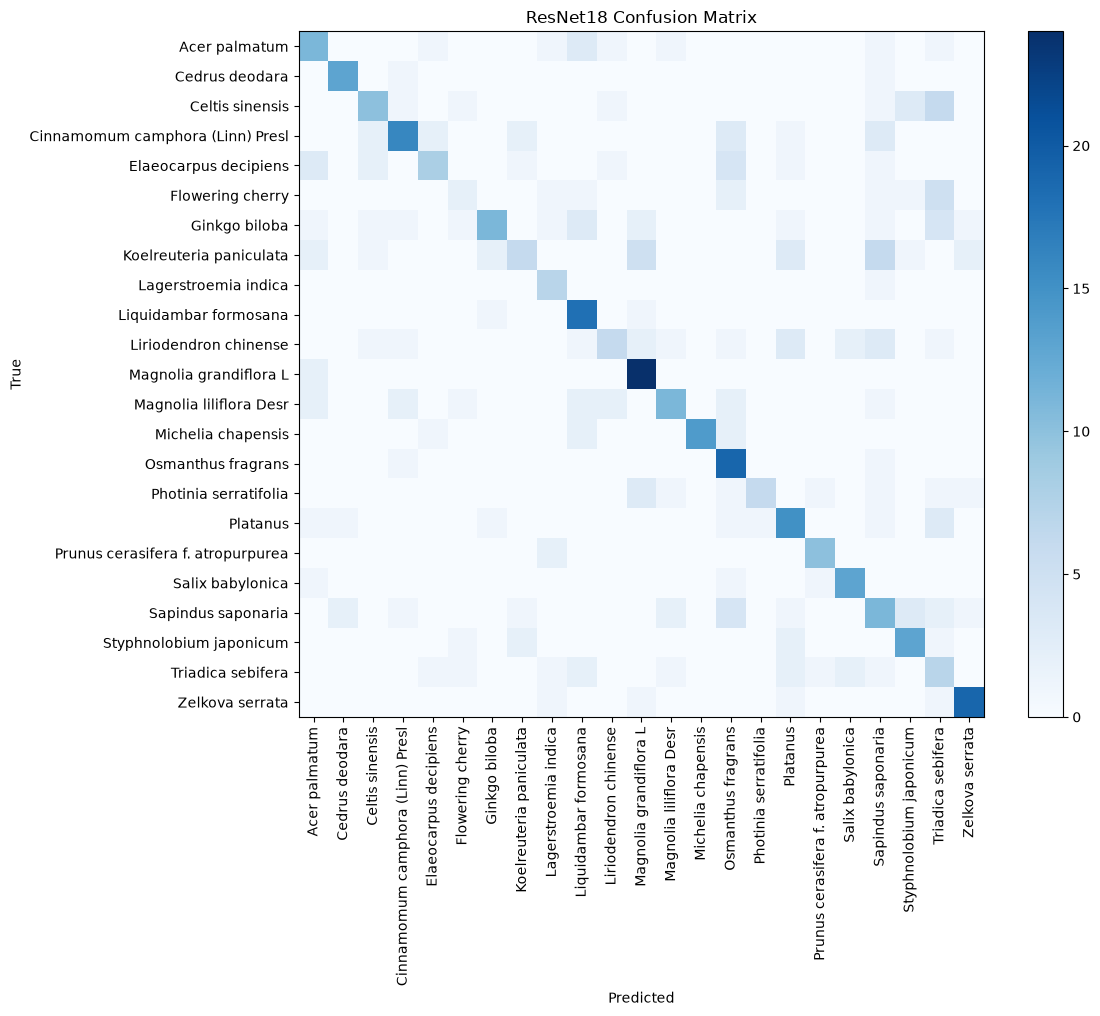

In [35]:
# Step 24 - Confusion matrix for ResNet18

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

all_labels = []
all_preds = []

resnet18.eval()

with torch.no_grad():
    for x, y in resnet_test_loader:
        x = x.to(device)

        outputs = resnet18(x)
        preds = outputs.argmax(dim=1)

        all_labels.extend(y.numpy())
        all_preds.extend(preds.cpu().numpy())

cm_resnet = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(12, 10))
plt.imshow(cm_resnet, cmap="Blues")
plt.colorbar()

class_names = resnet_test_ds.classes

plt.xticks(
    range(len(class_names)),
    class_names,
    rotation=90
)

plt.yticks(
    range(len(class_names)),
    class_names
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("ResNet18 Confusion Matrix")

plt.tight_layout()
plt.show()

**Note:**

Confusion matrix: 

- The diagonal shows many correct classifications across the 23 tree species, while off-diagonal cells reveal species that the ResNet18 confuses.

### Step 26 - Classification Report

In [36]:
# Step 26 - Classification report for ResNet18

from sklearn.metrics import classification_report

print("ResNet18 Classification Report:\n")

print(
    classification_report(
        all_labels,
        all_preds,
        target_names=class_names,
        digits=3
    )
)

ResNet18 Classification Report:

                                   precision    recall  f1-score   support

                    Acer palmatum      0.478     0.550     0.512        20
                   Cedrus deodara      0.812     0.867     0.839        15
                  Celtis sinensis      0.588     0.435     0.500        23
 Cinnamomum camphora (Linn) Presl      0.667     0.552     0.604        29
            Elaeocarpus decipiens      0.615     0.381     0.471        21
                 Flowering cherry      0.286     0.154     0.200        13
                    Ginkgo biloba      0.733     0.393     0.512        28
          Koelreuteria paniculata      0.500     0.214     0.300        28
             Lagerstroemia indica      0.500     0.875     0.636         8
            Liquidambar formosana      0.562     0.900     0.692        20
            Liriodendron chinense      0.545     0.273     0.364        22
           Magnolia grandiflora L      0.632     0.923     0.750  

**Note:**

Classification report: 

- ResNet18 achieved **57.2% test accuracy** and a **macro F1-score of 0.573**. 

- Performance varies between species, with some classes classified very well and others remaining difficult.

### Step 27 - Visualize some ResNet18 predictions

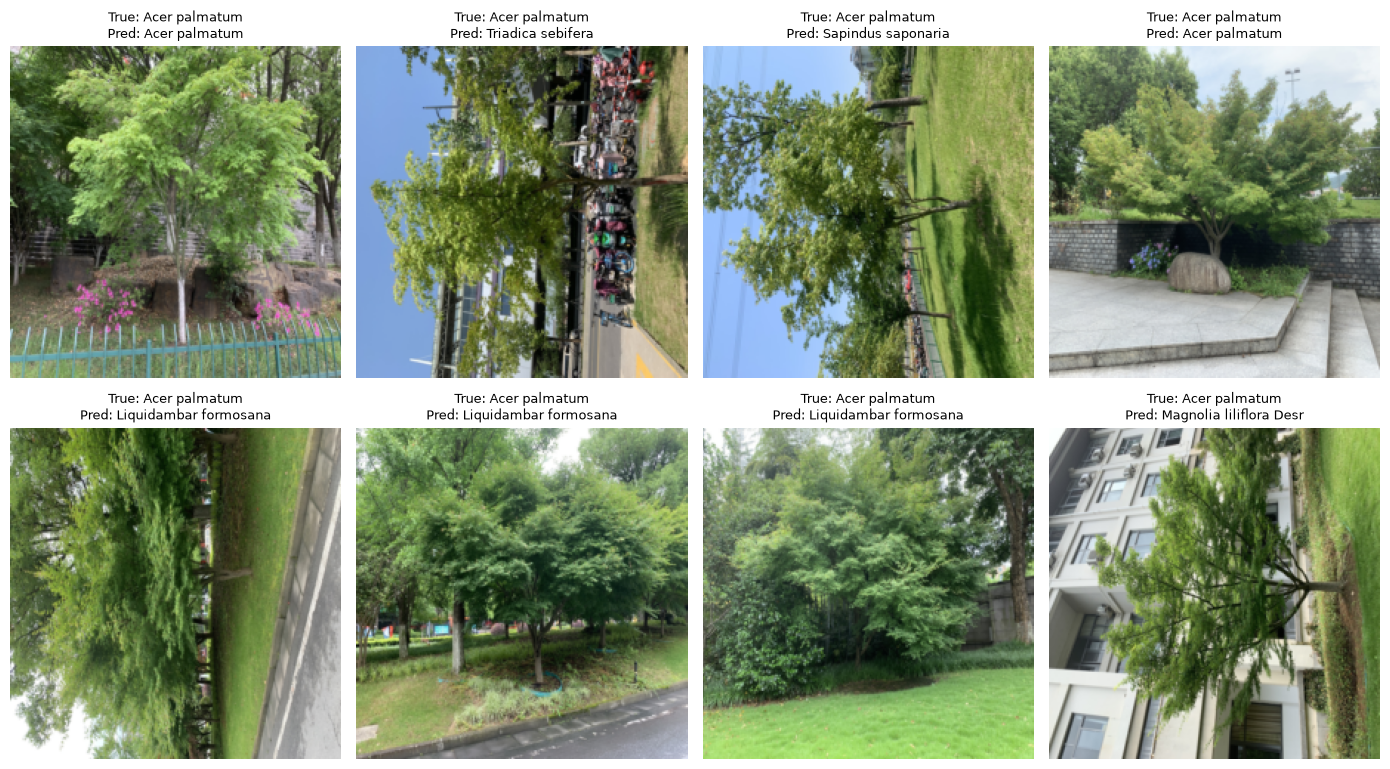

In [37]:
# Step 27 - Visualize ResNet18 predictions

import matplotlib.pyplot as plt

resnet18.eval()

images, labels = next(iter(resnet_test_loader))
images_device = images.to(device)

with torch.no_grad():
    outputs = resnet18(images_device)
    preds = outputs.argmax(dim=1).cpu()

# Show 8 examples
fig, axes = plt.subplots(2, 4, figsize=(14, 8))

for i, ax in enumerate(axes.flat):
    # Undo ImageNet normalization for display
    img = images[i].permute(1, 2, 0)

    mean = torch.tensor(imagenet_mean)
    std = torch.tensor(imagenet_std)

    img = img * std + mean
    img = img.clamp(0, 1)

    true_name = class_names[labels[i].item()]
    pred_name = class_names[preds[i].item()]

    ax.imshow(img)
    ax.set_title(
        f"True: {true_name}\nPred: {pred_name}",
        fontsize=9
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

**Note:**

Prediction visualization: 

- Visual inspection shows **both correct** and **incorrect predictions**. 

- Some images have difficult orientations/backgrounds, which may contribute to classification errors.

### Step 28 - Save the trained ResNet18 model

In [38]:
# Step 28 - Save trained ResNet18 model

model_path = "resnet18_tree_classifier.pth"

torch.save(resnet18.state_dict(), model_path)

print("Model saved successfully!")
print("Saved as:", model_path)

Model saved successfully!
Saved as: resnet18_tree_classifier.pth


**Note:**

- Saved the trained ResNet18 weights so the model can be reused without retraining.

# Day 04 - Augmentation Experiments 1 & 2 (25.09.2026)

# Experiment 1 - Improved Rotation Augmentation

During the ResNet18 prediction analysis, several incorrectly classified images appeared sideways or strongly rotated.

The previous ResNet18 training used only small random rotations. In this experiment, I will investigate whether stronger rotation augmentation helps the model handle different image orientations and improves classification performance.

The original dataset will remain unchanged. Rotation will be applied only to training images using PyTorch transformations.

The results will be compared with the ResNet18 baseline:

- Validation accuracy: 60.0%
- Test accuracy: 57.2%
- Macro F1-score: 0.573

### Step 1 - create the new rotation-aware training transform

In [30]:
import torch

In [ ]:
rotation_train_tfms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(degrees=90),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

print("Rotation-aware training transformations created.")

Rotation-aware training transformations created.


### Step 2 - create a separate training dataset and DataLoader

In [28]:
rotation_train_ds = datasets.ImageFolder(
    train_dir,
    transform=rotation_train_tfms
)

rotation_train_loader = DataLoader(
    rotation_train_ds,
    batch_size=32,
    shuffle=True
)

print("Training images:", len(rotation_train_ds))
print("Number of classes:", len(rotation_train_ds.classes))

Training images: 3850
Number of classes: 23


### Step 3 - visualize the augmentation

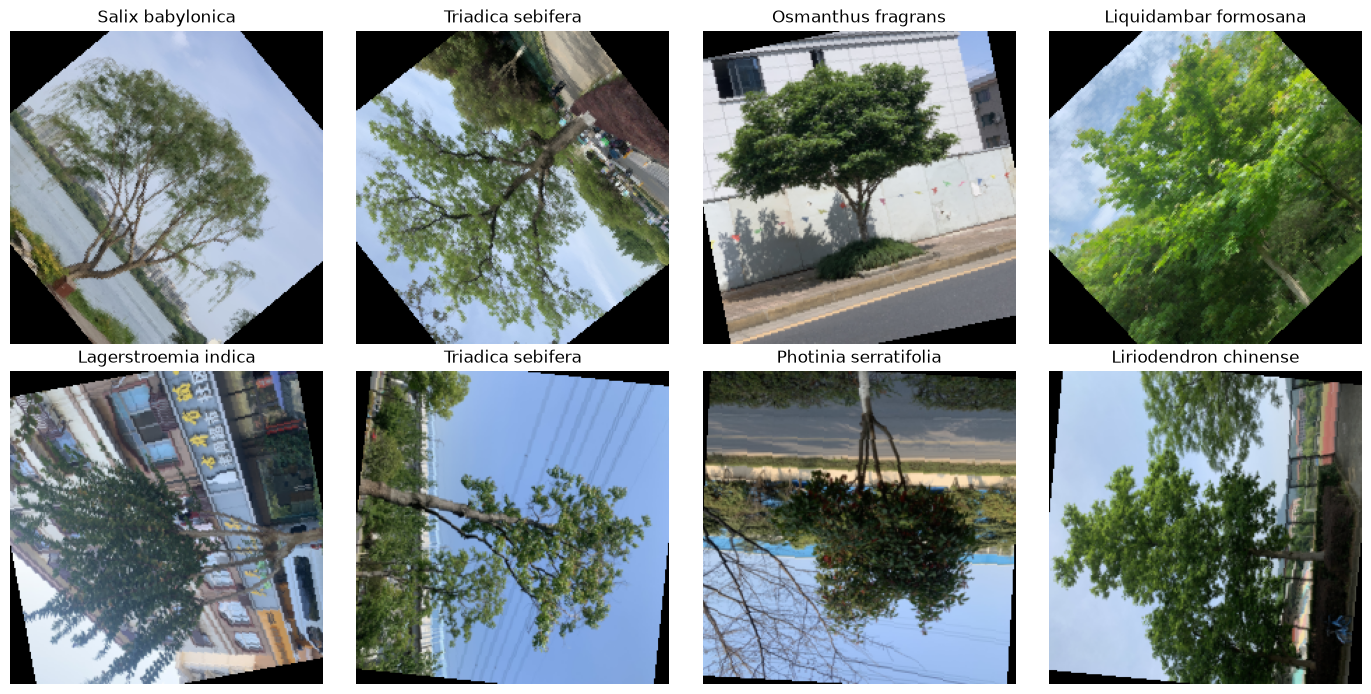

In [31]:
# Show rotation-augmented training images

images, labels = next(iter(rotation_train_loader))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, ax in enumerate(axes.flatten()):
    img = images[i].permute(1, 2, 0)

    # Undo ImageNet normalization for display
    mean = torch.tensor(imagenet_mean)
    std = torch.tensor(imagenet_std)
    img = img * std + mean
    img = img.clamp(0, 1)

    ax.imshow(img)
    ax.set_title(rotation_train_ds.classes[labels[i]])
    ax.axis("off")

plt.tight_layout()
plt.show()

### Step 4 - create a fresh ResNet18 for this experiment 

In [33]:
import torch.nn as nn

In [35]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [36]:
rotation_resnet18 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze pretrained layers
for param in rotation_resnet18.parameters():
    param.requires_grad = False

# Replace final layer for our 23 tree species
num_features = rotation_resnet18.fc.in_features
rotation_resnet18.fc = nn.Linear(num_features, 23)

# Move model to device
rotation_resnet18 = rotation_resnet18.to(device)

print("Fresh ResNet18 created for rotation experiment.")
print("Final layer:", rotation_resnet18.fc)

Fresh ResNet18 created for rotation experiment.
Final layer: Linear(in_features=512, out_features=23, bias=True)


### Step 5 - define the loss function and optimizer for this rotation experiment

In [37]:
criterion_rotation = nn.CrossEntropyLoss()

optimizer_rotation = torch.optim.Adam(
    rotation_resnet18.fc.parameters(),
    lr=0.001
)

print("Loss function and optimizer ready.")

Loss function and optimizer ready.


### Step 6 - recreate the validation loader

In [39]:
resnet_val_ds = datasets.ImageFolder(
    val_dir,
    transform=resnet_eval_tfms
)

resnet_val_loader = DataLoader(
    resnet_val_ds,
    batch_size=32,
    shuffle=False
)

print("Validation images:", len(resnet_val_ds))
print("Validation loader ready.")

Validation images: 482
Validation loader ready.


### Step 7 - Train for 5 epochs

In [41]:
import time

EPOCHS_ROTATION = 5

for epoch in range(2, EPOCHS_ROTATION + 1):
    start = time.time()

    # ----- TRAINING -----
    rotation_resnet18.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for x, y in rotation_train_loader:
        x, y = x.to(device), y.to(device)

        optimizer_rotation.zero_grad()

        outputs = rotation_resnet18(x)
        loss = criterion_rotation(outputs, y)

        loss.backward()
        optimizer_rotation.step()

        train_loss += loss.item() * x.size(0)

        preds = outputs.argmax(dim=1)
        train_correct += (preds == y).sum().item()
        train_total += y.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    # ----- VALIDATION -----
    rotation_resnet18.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for x, y in resnet_val_loader:
            x, y = x.to(device), y.to(device)

            outputs = rotation_resnet18(x)
            loss = criterion_rotation(outputs, y)

            val_loss += loss.item() * x.size(0)

            preds = outputs.argmax(dim=1)
            val_correct += (preds == y).sum().item()
            val_total += y.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    elapsed = time.time() - start

    print(
        f"Epoch {epoch}/{EPOCHS_ROTATION} | "
        f"train_loss={train_loss:.4f} "
        f"train_acc={train_acc:.3f} | "
        f"val_loss={val_loss:.4f} "
        f"val_acc={val_acc:.3f} | "
        f"time={elapsed:.1f}s"
    )

Epoch 2/5 | train_loss=2.2055 train_acc=0.390 | val_loss=2.0075 val_acc=0.434 | time=238.4s
Epoch 3/5 | train_loss=2.0041 train_acc=0.444 | val_loss=1.7957 val_acc=0.519 | time=235.7s
Epoch 4/5 | train_loss=1.8600 train_acc=0.474 | val_loss=1.7530 val_acc=0.492 | time=226.1s
Epoch 5/5 | train_loss=1.7863 train_acc=0.495 | val_loss=1.7214 val_acc=0.517 | time=225.8s


### Step 8 - recreate the test loader

In [43]:
resnet_test_ds = datasets.ImageFolder(
    test_dir,
    transform=resnet_eval_tfms
)

resnet_test_loader = DataLoader(
    resnet_test_ds,
    batch_size=32,
    shuffle=False
)

print("Test images:", len(resnet_test_ds))
print("Test loader ready.")

Test images: 472
Test loader ready.


### Step 9 - test the rotation model

In [44]:
# Test the rotation-augmented ResNet18

rotation_resnet18.eval()

test_loss = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():
    for x, y in resnet_test_loader:
        x, y = x.to(device), y.to(device)

        outputs = rotation_resnet18(x)
        loss = criterion_rotation(outputs, y)

        test_loss += loss.item() * x.size(0)

        preds = outputs.argmax(dim=1)
        test_correct += (preds == y).sum().item()
        test_total += y.size(0)

test_loss /= test_total
test_acc = test_correct / test_total

print(f"Rotation experiment test loss: {test_loss:.4f}")
print(f"Rotation experiment test accuracy: {test_acc:.3f}")
print(f"Correct predictions: {test_correct}/{test_total}")

Rotation experiment test loss: 1.8059
Rotation experiment test accuracy: 0.489
Correct predictions: 231/472


### Experiment 1 - Rotation Augmentation - Conclusion

The original ResNet18 achieved 57.2% test accuracy (270/472 correct predictions).

After inspecting the original model's incorrect predictions, several images appeared sideways or rotated. Therefore, stronger rotation augmentation (`RandomRotation(degrees=90)`) was tested during training.

The rotation-augmented model achieved 48.9% test accuracy (231/472 correct predictions), which was lower than the original model.

This experiment shows that aggressive random rotation did not improve the model. The augmentation may have made the training task too difficult by introducing many strongly rotated images. Therefore, a less aggressive or more controlled preprocessing strategy could be investigated in a future experiment.

# Experiment 2 - Gentle rotation augmentation

### Step 1 - create the new rotation-aware training transform

In [45]:
gentle_train_tfms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

print("Gentle rotation transformations created.")

Gentle rotation transformations created.


### Step 2 - create the training dataset and loader

In [46]:
# Experiment 2 - Dataset and DataLoader

gentle_train_ds = datasets.ImageFolder(
    train_dir,
    transform=gentle_train_tfms
)

gentle_train_loader = DataLoader(
    gentle_train_ds,
    batch_size=32,
    shuffle=True
)

print("Training images:", len(gentle_train_ds))
print("Number of classes:", len(gentle_train_ds.classes))
print("Gentle rotation DataLoader ready.")

Training images: 3850
Number of classes: 23
Gentle rotation DataLoader ready.


### Step 3 - Create a fresh ResNet18

In [47]:
# Experiment 2 - Fresh ResNet18

gentle_resnet18 = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Freeze pretrained layers
for param in gentle_resnet18.parameters():
    param.requires_grad = False

# Replace final layer for 23 tree species
num_features = gentle_resnet18.fc.in_features
gentle_resnet18.fc = nn.Linear(num_features, 23)

# Move model to device
gentle_resnet18 = gentle_resnet18.to(device)

print("Fresh ResNet18 created for gentle rotation experiment.")
print("Final layer:", gentle_resnet18.fc)

Fresh ResNet18 created for gentle rotation experiment.
Final layer: Linear(in_features=512, out_features=23, bias=True)


### Step 4 - Loss function and optimizer

In [48]:
# Experiment 2 - Loss and optimizer

criterion_gentle = nn.CrossEntropyLoss()

optimizer_gentle = torch.optim.Adam(
    gentle_resnet18.fc.parameters(),
    lr=0.001
)

print("Loss function and optimizer ready.")

Loss function and optimizer ready.


### Step 5 - Train gentle-rotation ResNet18

In [49]:
import time

EPOCHS_GENTLE = 10

for epoch in range(1, EPOCHS_GENTLE + 1):
    start = time.time()

    # ----- TRAINING -----
    gentle_resnet18.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for x, y in gentle_train_loader:
        x, y = x.to(device), y.to(device)

        optimizer_gentle.zero_grad()

        outputs = gentle_resnet18(x)
        loss = criterion_gentle(outputs, y)

        loss.backward()
        optimizer_gentle.step()

        train_loss += loss.item() * x.size(0)

        preds = outputs.argmax(dim=1)
        train_correct += (preds == y).sum().item()
        train_total += y.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    # ----- VALIDATION -----
    gentle_resnet18.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for x, y in resnet_val_loader:
            x, y = x.to(device), y.to(device)

            outputs = gentle_resnet18(x)
            loss = criterion_gentle(outputs, y)

            val_loss += loss.item() * x.size(0)

            preds = outputs.argmax(dim=1)
            val_correct += (preds == y).sum().item()
            val_total += y.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    elapsed = time.time() - start

    print(
        f"Epoch {epoch}/{EPOCHS_GENTLE} | "
        f"train_loss={train_loss:.4f} "
        f"train_acc={train_acc:.3f} | "
        f"val_loss={val_loss:.4f} "
        f"val_acc={val_acc:.3f} | "
        f"time={elapsed:.1f}s"
    )

Epoch 1/10 | train_loss=2.7742 train_acc=0.206 | val_loss=2.2432 val_acc=0.361 | time=231.6s
Epoch 2/10 | train_loss=2.1370 train_acc=0.430 | val_loss=1.8729 val_acc=0.494 | time=233.8s
Epoch 3/10 | train_loss=1.8772 train_acc=0.486 | val_loss=1.6564 val_acc=0.579 | time=226.0s
Epoch 4/10 | train_loss=1.6790 train_acc=0.549 | val_loss=1.5495 val_acc=0.598 | time=224.7s
Epoch 5/10 | train_loss=1.5632 train_acc=0.558 | val_loss=1.5163 val_acc=0.562 | time=224.0s
Epoch 6/10 | train_loss=1.5102 train_acc=0.575 | val_loss=1.3936 val_acc=0.610 | time=227.3s
Epoch 7/10 | train_loss=1.3992 train_acc=0.600 | val_loss=1.3395 val_acc=0.614 | time=233.5s
Epoch 8/10 | train_loss=1.3570 train_acc=0.611 | val_loss=1.3067 val_acc=0.624 | time=238.9s
Epoch 9/10 | train_loss=1.3249 train_acc=0.627 | val_loss=1.3037 val_acc=0.637 | time=236.9s
Epoch 10/10 | train_loss=1.2649 train_acc=0.634 | val_loss=1.3079 val_acc=0.620 | time=236.2s


### Step 6 - test the gentle rotation model

In [50]:
gentle_resnet18.eval()

test_loss = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():
    for x, y in resnet_test_loader:
        x, y = x.to(device), y.to(device)

        outputs = gentle_resnet18(x)
        loss = criterion_gentle(outputs, y)

        test_loss += loss.item() * x.size(0)

        preds = outputs.argmax(dim=1)
        test_correct += (preds == y).sum().item()
        test_total += y.size(0)

test_loss /= test_total
test_acc = test_correct / test_total

print(f"Gentle rotation test loss: {test_loss:.4f}")
print(f"Gentle rotation test accuracy: {test_acc:.3f}")
print(f"Correct predictions: {test_correct}/{test_total}")

Gentle rotation test loss: 1.5054
Gentle rotation test accuracy: 0.600
Correct predictions: 283/472


### Step 7 - Visual predictions

In [52]:
import numpy as np

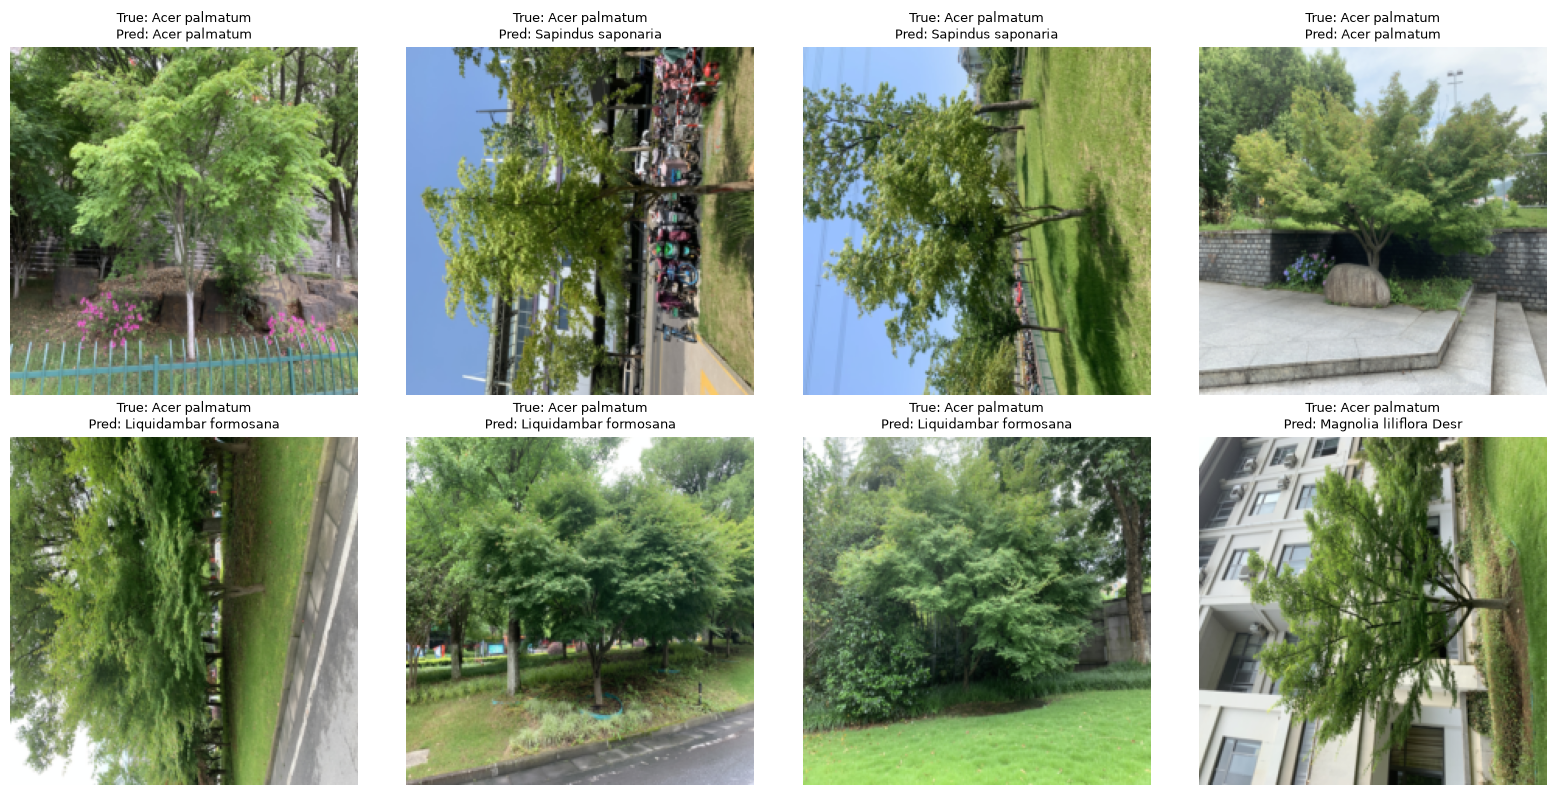

In [53]:
# Experiment 2 - Visual prediction check

gentle_resnet18.eval()

images, labels = next(iter(resnet_test_loader))
images_device = images.to(device)

with torch.no_grad():
    outputs = gentle_resnet18(images_device)
    predictions = outputs.argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i, ax in enumerate(axes.flatten()):
    img = images[i].permute(1, 2, 0).numpy()

    # Undo ImageNet normalization for display
    mean = np.array(imagenet_mean)
    std = np.array(imagenet_std)
    img = std * img + mean
    img = np.clip(img, 0, 1)

    true_name = resnet_test_ds.classes[labels[i]]
    pred_name = resnet_test_ds.classes[predictions[i]]

    ax.imshow(img)
    ax.set_title(
        f"True: {true_name}\nPred: {pred_name}",
        fontsize=9
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

### Step 8 - Collect predictions

In [54]:
# Experiment 2 - Collect test predictions

gentle_resnet18.eval()

all_true_gentle = []
all_pred_gentle = []

with torch.no_grad():
    for x, y in resnet_test_loader:
        x = x.to(device)

        outputs = gentle_resnet18(x)
        preds = outputs.argmax(dim=1).cpu()

        all_true_gentle.extend(y.numpy())
        all_pred_gentle.extend(preds.numpy())

print("Predictions collected:", len(all_pred_gentle))

Predictions collected: 472


### Step 9 - Plot Experiment 2 confusion matrix

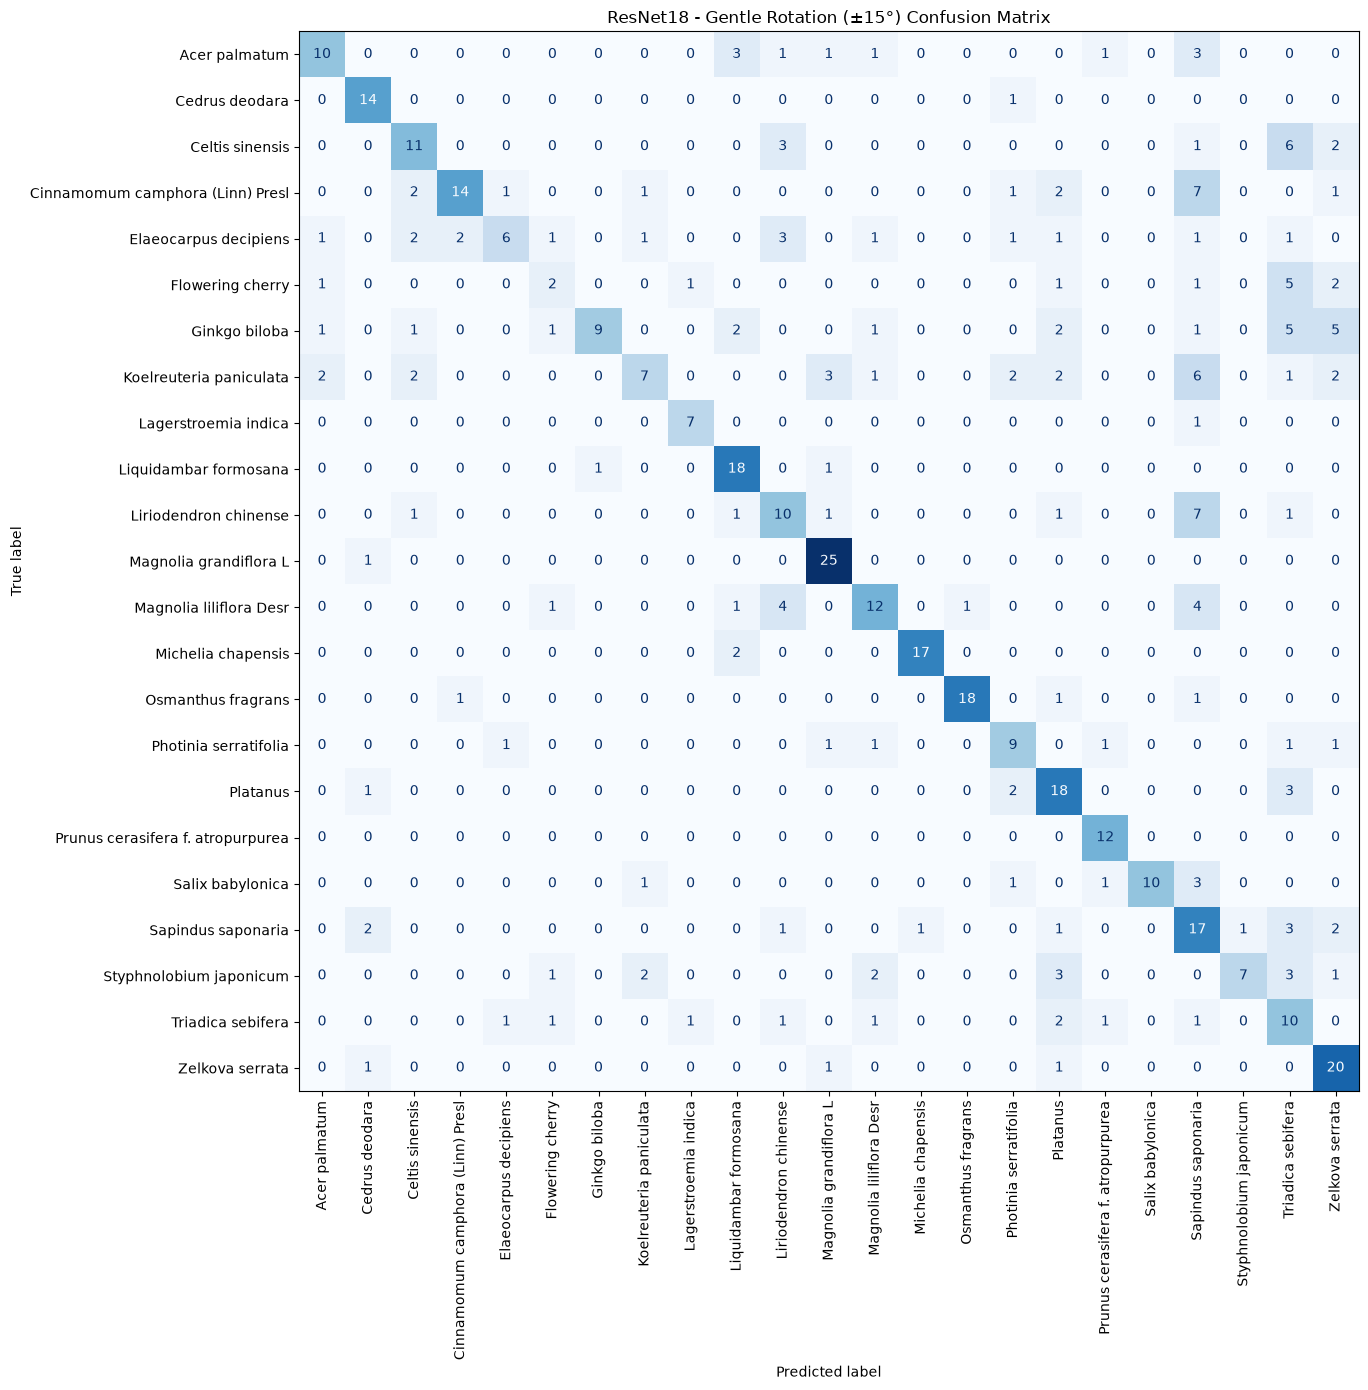

In [55]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_gentle = confusion_matrix(
    all_true_gentle,
    all_pred_gentle
)

fig, ax = plt.subplots(figsize=(14, 14))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_gentle,
    display_labels=resnet_test_ds.classes
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False
)

plt.title("ResNet18 - Gentle Rotation (±15°) Confusion Matrix")
plt.tight_layout()
plt.show()

### What we've learned from the experiments

- Strong rotation augmentation `(±90°)` reduced test accuracy from `57.2% to 48.9%`. 

- A gentler rotation augmentation `(±15°)`, combined with longer training, increased test accuracy to `60.0%`. 

- Visual inspection showed that orientation alone was not responsible for all classification errors, since some sideways Acer palmatum images remained incorrectly classified.